In [1]:
import sys
sys.path.append("/Experiments/riccardop02")


from dotenv import load_dotenv
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1" 
os.environ["HF_HOME"] = "/Experiments/riccardop02/huggingface"


import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

### DINOV3

MODEL_DINOv3 = "facebook/dinov3-vitb16-pretrain-lvd1689m"
load_dotenv()
hf_token = os.getenv("HF_TOKEN")



processorv3 = AutoImageProcessor.from_pretrained(MODEL_DINOv3)
dinov3 = AutoModel.from_pretrained(MODEL_DINOv3, token= hf_token).to(device).eval()


for p in dinov3.parameters():
    p.requires_grad_(False)


### DINOV2

MODEL_DINOv2 = "facebook/dinov2-base"

processorv2 = AutoImageProcessor.from_pretrained(MODEL_DINOv2)
dinov2 = AutoModel.from_pretrained(MODEL_DINOv2).to(device).eval()

for p in dinov2.parameters():
    p.requires_grad_(False)


n_params = sum(p.numel() for p in dinov3.parameters())
print(f"{MODEL_DINOv3} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", dinov3.config.patch_size, "| hidden dim:", dinov3.config.hidden_size)

print("-"*15)

n_params = sum(p.numel() for p in dinov2.parameters())
print(f"{MODEL_DINOv2} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", dinov2.config.patch_size, "| hidden dim:", dinov2.config.hidden_size)



/Experiments/riccardop02/poseJepa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 6551.40it/s]

facebook/dinov3-vitb16-pretrain-lvd1689m caricato — 85.7M parametri
patch size: 16 | hidden dim: 768
---------------
facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [2]:
import torch.nn.functional as F

@torch.no_grad()
def extract_featuresv2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processorv2(images=img, return_tensors="pt").to(device)
    hs = dinov2(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "PatchToken":
            v = h[1:]
        elif token == "ptc":
            v = h[1:].flatten()
        elif token == "pool":
            P = h[1:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

print("Extractv2 Features Ready!")


import torch.nn.functional as F

@torch.no_grad()
def extract_featuresv3(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processorv3(images=img, return_tensors="pt").to(device)
    hs = dinov3(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "PatchToken":
            v = h[5:]
        elif token == "ptc":
            v = h[5:].flatten()
        elif token == "pool":
            P = h[5:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

print("Extractv3 Features Ready!")

Extractv2 Features Ready!
Extractv3 Features Ready!


In [3]:
# SAMPLE 20 photo per database to create a generic database

import os
import random
import numpy as np
from PIL import Image
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ================= CONFIG =================


DATASETS = ["icbin", "lmo", "ycbv"]   # sottocartelle dentro RENDERS
N_PER_DATASET = 50                   # immagini da campionare per ciascun dataset
SEED = 42
K = 50                              # Components PCA

extract_kwargs = dict(layers=[-1], token="PatchToken",
                       norm_mode="global", normalize=True)

# ================= UTILITY DI CAMPIONAMENTO =================

def collect_image_paths(folder):
    paths = []
    for root, _, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(".png"):
                paths.append(os.path.join(root, f))
    
    return paths


def sample_per_dataset(renders_root, dataset_names, n_per_dataset, seed=SEED):
    """
    Ritorna:
        img_paths: lista di path (concatenati, in ordine dataset)
        labels: lista parallela con il nome del dataset di provenienza
    """
    random.seed(seed)
    img_paths, labels = [], []

    for ds in dataset_names:
        ds_folder = os.path.join(renders_root, ds)
        all_paths = collect_image_paths(ds_folder)
        if len(all_paths) < n_per_dataset:
            raise ValueError(
                f"Dataset '{ds}': richieste {n_per_dataset} immagini ma trovate solo {len(all_paths)}."
            )
        sampled = random.sample(all_paths, n_per_dataset)
        img_paths.extend(sampled)
        labels.extend([ds] * n_per_dataset)

    return img_paths, labels

# ================= ESTRAZIONE FEATURE =================

def build_feature_matrix(img_paths, extract_fn, **extract_kwargs):
    feats = []
    for p in img_paths:
        img = Image.open(p).convert("RGB")
        v = extract_fn(img, **extract_kwargs)
        feats.append(v.cpu().numpy())
    return np.stack(feats, axis=0)

# ================= PCA =================

def compute_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    proj = pca.fit_transform(features)
    return pca

# ================= PIPELINE =================

img_paths, labels = sample_per_dataset(RENDERS, DATASETS, N_PER_DATASET, seed=SEED)
labels = np.array(labels)

print(f"Totale immagini campionate: {len(img_paths)} "
      f"({N_PER_DATASET} x {len(DATASETS)} dataset)")

print("Estraggo feature DINOv2...")
feats_v2 = build_feature_matrix(img_paths, extract_featuresv2, **extract_kwargs)

print("Estraggo feature DINOv3...")
feats_v3 = build_feature_matrix(img_paths, extract_featuresv3, **extract_kwargs)

N2, S2, C2 = feats_v2.shape
N3, S3, C3 = feats_v3.shape


feats_v2 = feats_v2.reshape(N2*S2, C2)
feats_v3 = feats_v3.reshape(N3*S3, C3)

print("Feature v2 shape:", feats_v2.shape)
print("Feature v3 shape:", feats_v3.shape)

pca_v2 = compute_pca(feats_v2, n_components=K)
pca_v3 = compute_pca(feats_v3, n_components=K)

feats_v2 = feats_v2.reshape(N2,S2, C2)
feats_v3 = feats_v3.reshape(N3,S3, C3)

print("DINOv2 - varianza spiegata:", pca_v2.explained_variance_ratio_.sum())
print("DINOv3 - varianza spiegata:", pca_v3.explained_variance_ratio_.sum())


print("Feature v2 shape:", feats_v2.shape)
print("Feature v3 shape:", feats_v3.shape)



Totale immagini campionate: 150 (50 x 3 dataset)
Estraggo feature DINOv2...
Estraggo feature DINOv3...
Feature v2 shape: (38400, 768)
Feature v3 shape: (29400, 768)
DINOv2 - varianza spiegata: 0.73574704
DINOv3 - varianza spiegata: 0.81083894
Feature v2 shape: (150, 256, 768)
Feature v3 shape: (150, 196, 768)


In [4]:

_extract_featuresv2_original = extract_featuresv2

def extract_featuresv2(img, layers=[-1], token="pool", grid=2,
                        norm_mode="global", normalize=True,
                        pca_model=None):

    if token == "PCA":
        if pca_model is None:
            raise ValueError("token='PCA' richiede di passare pca_model (una PCA già fittata).")

        feat = _extract_featuresv2_original(
            img, layers=layers, token="PatchToken",
            grid=grid, norm_mode=norm_mode, normalize=normalize
        )                                          # (n_patch, 768)

        X = feat.cpu().numpy()
        X_reduced = pca_model.transform(X)          # (n_patch, K)
        return torch.tensor(X_reduced, dtype=torch.float32, device=feat.device)

    # per qualunque altro token, comportamento identico all'originale
    return _extract_featuresv2_original(
        img, layers=layers, token=token, grid=grid,
        norm_mode=norm_mode, normalize=normalize
    )


_extract_featuresv3_original = extract_featuresv3

def extract_featuresv3(img, layers=[-1], token="pool", grid=2,
                        norm_mode="global", normalize=True,
                        pca_model=None):
    """
    Wrapper attorno alla extract_featuresv3 originale.

    token="PCA" -> estrae i PatchToken (768-d) e li proietta
                   con una PCA già fittata (pca_model), riducendo
                   la dimensione canale a K.

    pca_model: oggetto sklearn.decomposition.PCA già fittato
               (es. pca_v3 ottenuto da compute_pca in precedenza).
               Obbligatorio se token="PCA".
    """
    if token == "PCA":
        if pca_model is None:
            raise ValueError("token='PCA' richiede di passare pca_model (una PCA già fittata).")

        feat = _extract_featuresv3_original(
            img, layers=layers, token="PatchToken",
            grid=grid, norm_mode=norm_mode, normalize=normalize
        )                                          # (n_patch, 768)

        X = feat.cpu().numpy()
        X_reduced = pca_model.transform(X)          # (n_patch, K)
        return torch.tensor(X_reduced, dtype=torch.float32, device=feat.device)

    # per qualunque altro token, comportamento identico all'originale
    return _extract_featuresv3_original(
        img, layers=layers, token=token, grid=grid,
        norm_mode=norm_mode, normalize=normalize
    )


print("Wrapper PCA per extract_featuresv2 e extract_featuresv3 pronti!")


Wrapper PCA per extract_featuresv2 e extract_featuresv3 pronti!


# EXPERIMENT 1

/tmp/ipykernel_339247/2433663115.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


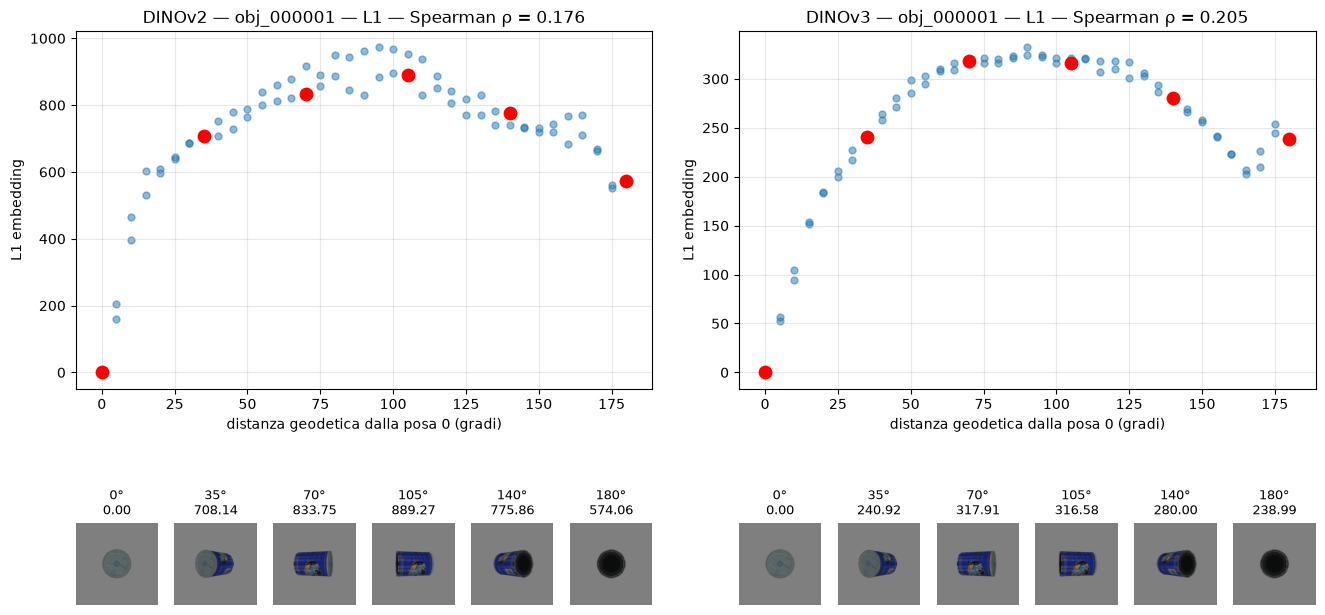

/tmp/ipykernel_339247/2433663115.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


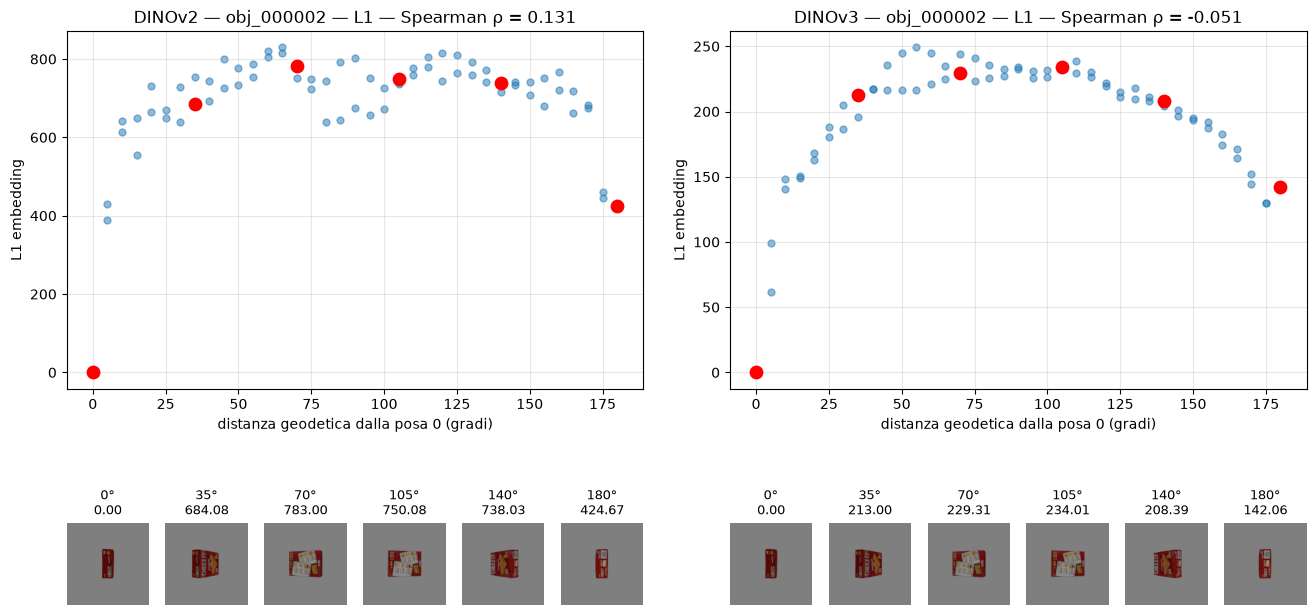

/tmp/ipykernel_339247/2433663115.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


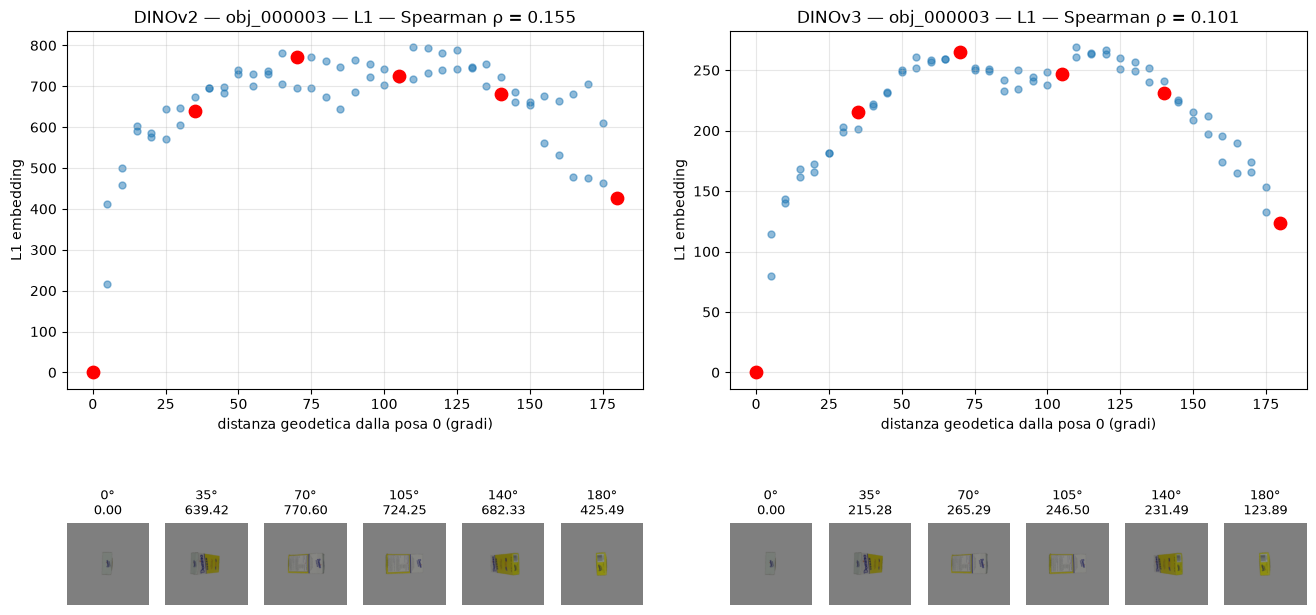

/tmp/ipykernel_339247/2433663115.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


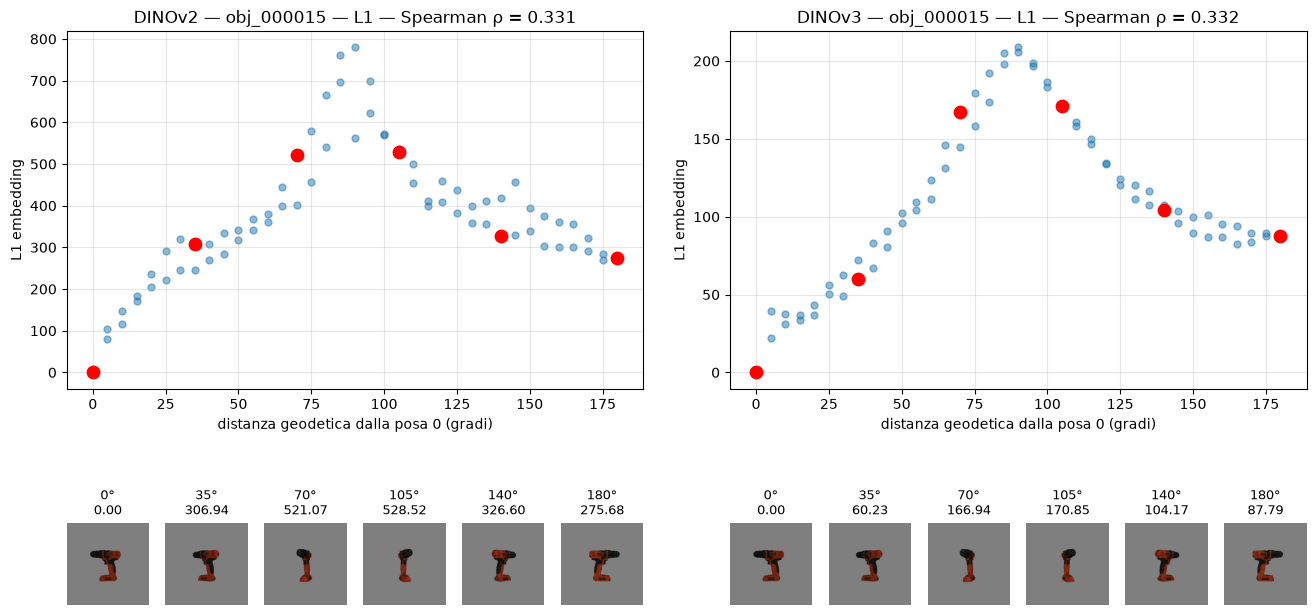

In [7]:
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr
from PIL import Image
import matplotlib.pyplot as plt


def _compute_angles_dists(df, R_all, extract_fn, layers, token, pca_model, metric, dataset):
    """
    Calcola angoli geodetici e distanze di embedding per un singolo modello
    (extract_fn = extract_featuresv2 o extract_featuresv3, con relativa pca_model).
    """
    R_ref = R_all[0]
    e_ref = extract_fn(
        Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
        layers=layers, token=token, pca_model=pca_model
    )
    # se il token è "PCA" (o comunque multi-patch), appiattiamo per confronto globale
    if e_ref.dim() > 1:
        e_ref = e_ref.flatten()

    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi

        e = extract_fn(
            Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
            layers=layers, token=token, pca_model=pca_model
        )
        if e.dim() > 1:
            e = e.flatten()

        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)

        dists.append(d)
        angles.append(ang)

    return np.array(angles), np.array(dists)


def plot_object_comparison(obj_name, dataset="ycbv", layers=[-1], token="PCA",
                            pca_v2=None, pca_v3=None, metric="L1"):
    """
    Versione affiancata: DINOv2 (sinistra) vs DINOv3 (destra), stesso oggetto/pose.

    token="PCA" -> richiede pca_v2 e pca_v3 (PCA già fittate, es. da compute_pca).
    Per usare token diverso da "PCA" (es. "cls", "pool"), pca_v2/pca_v3 possono
    restare None: i wrapper li ignorano se token != "PCA".
    """
    if token == "PCA" and (pca_v2 is None or pca_v3 is None):
        raise ValueError("token='PCA' richiede sia pca_v2 che pca_v3.")

    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. calcola angoli/distanze per entrambi i modelli
    angles_v2, dists_v2 = _compute_angles_dists(
        df, R_all, extract_featuresv2, layers, token, pca_v2, metric, dataset)
    angles_v3, dists_v3 = _compute_angles_dists(
        df, R_all, extract_featuresv3, layers, token, pca_v3, metric, dataset)

    rho_v2, _ = spearmanr(angles_v2, dists_v2)
    rho_v3, _ = spearmanr(angles_v3, dists_v3)

    # 6 viste equispaziate (usiamo l'ordine di v2 come riferimento comune, angoli identici)
    order = np.argsort(angles_v2)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: 2 colonne (v2 | v3), ognuna con scatter sopra + 6 viste sotto ---
    fig = plt.figure(figsize=(16, 8))
    outer = fig.add_gridspec(2, 2, height_ratios=[3, 1.4], hspace=0.35, wspace=0.15)

    model_data = [
        ("DINOv2", angles_v2, dists_v2, rho_v2, 0),
        ("DINOv3", angles_v3, dists_v3, rho_v3, 1),
    ]

    for name, angles, dists, rho, col in model_data:
        ax_scatter = fig.add_subplot(outer[0, col])
        ax_scatter.scatter(angles, dists, s=25, alpha=0.5)
        ax_scatter.scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
        ax_scatter.set_xlabel("distanza geodetica dalla posa 0 (gradi)")
        ax_scatter.set_ylabel(f"{metric} embedding")
        ax_scatter.set_title(f"{name} — {obj_name} — {metric} — Spearman ρ = {rho:.3f}")
        ax_scatter.grid(alpha=0.3)

        gs_views = outer[1, col].subgridspec(1, 6)
        for k, idx in enumerate(sel):
            ax = fig.add_subplot(gs_views[0, k])
            ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
            ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
            ax.axis("off")

    plt.tight_layout()
    plt.show()



OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object_comparison(obj, metric="L1", token="PCA",
                            pca_v2=pca_v2, pca_v3=pca_v3)

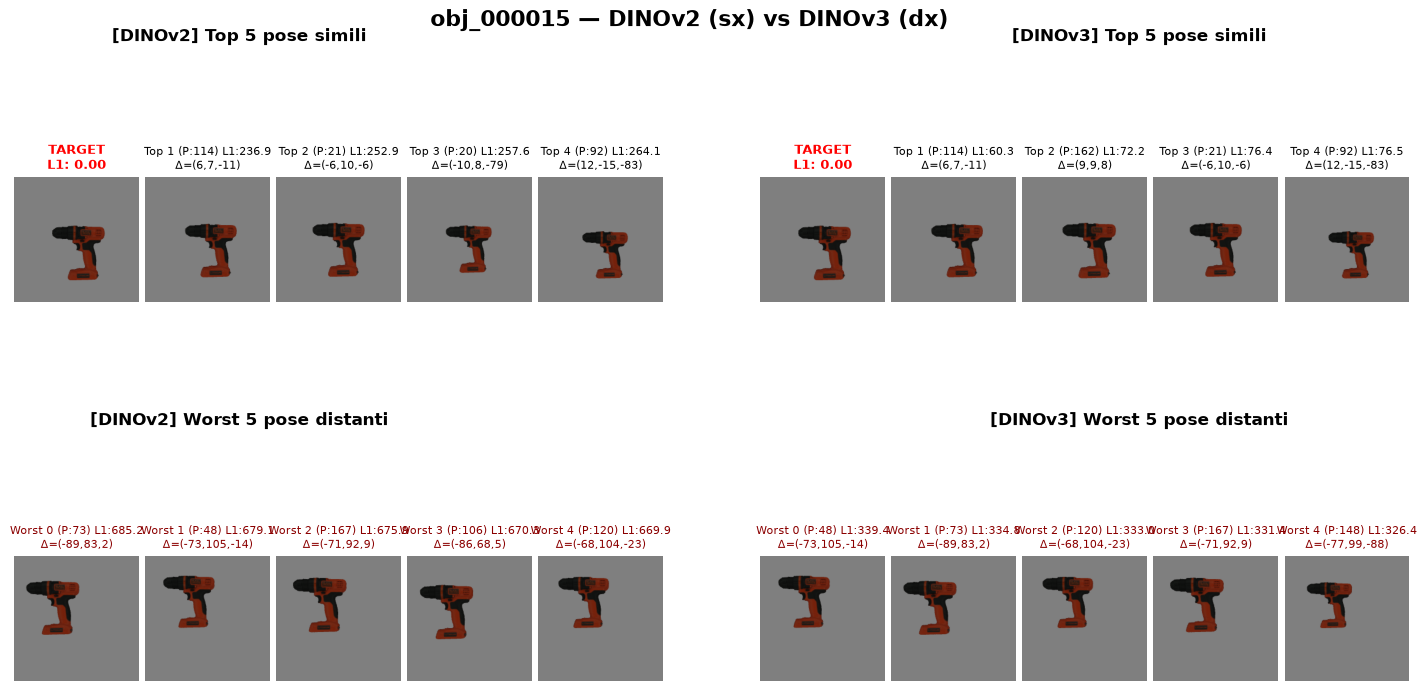

In [10]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def _compute_L1(img_paths, extract_fn, token, grid, pca_model):
    e_ref = extract_fn(Image.open(img_paths[0]).convert("RGB"),
                        token=token, grid=grid, pca_model=pca_model)
    if e_ref.dim() > 1:
        e_ref = e_ref.flatten()

    L1 = []
    for p in img_paths:
        e = extract_fn(Image.open(p).convert("RGB"),
                        token=token, grid=grid, pca_model=pca_model)
        if e.dim() > 1:
            e = e.flatten()
        L1.append(torch.abs(e_ref - e).sum().item())
    return np.array(L1)


def visualizza_embedding_3d_plotly_comparison(obj_name, dataset="ycbv_translation",
                                               token="PCA", grid=2, K=10, W=5,
                                               pca_v2=None, pca_v3=None):
    """
    Versione affiancata: DINOv2 (sinistra) vs DINOv3 (destra), stesso oggetto/pose,
    nello spazio 3D delle traslazioni.

    token="PCA" -> richiede pca_v2 e pca_v3 (PCA già fittate, es. da compute_pca).
    Per usare token diverso da "PCA" (es. "pool", "cls"), pca_v2/pca_v3 possono
    restare None: i wrapper li ignorano se token != "PCA".
    """
    if token == "PCA" and (pca_v2 is None or pca_v3 is None):
        raise ValueError("token='PCA' richiede sia pca_v2 che pca_v3.")

    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    T = df[["tx", "ty", "tz"]].values
    t_ref = T[0]

    img_paths = [RENDERS / img_path for img_path in df["image"]]

    # embedding + L1 per entrambi i modelli
    L1_v2 = _compute_L1(img_paths, extract_featuresv2, token, grid, pca_v2)
    L1_v3 = _compute_L1(img_paths, extract_featuresv3, token, grid, pca_v3)

    # angoli/traslazioni per correlazione (usiamo la distanza euclidea da t_ref
    # come "ground truth" di riferimento nello spazio traslazioni)
    pose_dist = np.linalg.norm(T - t_ref, axis=1)
    rho_v2, _ = spearmanr(pose_dist, L1_v2)
    rho_v3, _ = spearmanr(pose_dist, L1_v3)

    custom_colors = [[0.0, "red"], [0.3, "yellow"], [1.0, "blue"]]

    # ================= FIGURA 3D AFFIANCATA (2 scene, colorscale condivisa) =================
    # NB: normalizziamo ogni L1 nel proprio [0,1] (min-max) cosi' il colore
    # rappresenta la posizione RELATIVA all'interno di ciascun modello ed e'
    # confrontabile visivamente tra i due plot. Il valore assoluto di L1 resta
    # comunque leggibile nell'hover/testo, ma NON e' un indicatore di "modello
    # migliore": la scala grezza dipende dalla varianza dei componenti PCA di
    # ciascun modello, non dalla sua capacita' discriminativa. Per quello guarda
    # rho (Spearman) nel titolo: piu' alto = il modello separa meglio pose vicine
    # da pose lontane.

    def _norm01(x):
        return (x - x.min()) / (x.max() - x.min() + 1e-8)

    L1_v2_norm = _norm01(L1_v2)
    L1_v3_norm = _norm01(L1_v3)

    fig = make_subplots(
        rows=1, cols=2,
        specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
        subplot_titles=(f"DINOv2 — {obj_name} — ρ={rho_v2:.3f}",
                         f"DINOv3 — {obj_name} — ρ={rho_v3:.3f}")
    )

    model_data = [
        ("DINOv2", L1_v2, L1_v2_norm, 1),
        ("DINOv3", L1_v3, L1_v3_norm, 2),
    ]

    for name, L1, L1_norm, col in model_data:
        indici_ordinati = np.argsort(L1)
        indici_top_k = indici_ordinati[:K]
        indici_worst_w = indici_ordinati[-W:][::-1]

        fig.add_trace(go.Scatter3d(
            x=T[:, 0], y=T[:, 1], z=T[:, 2],
            mode='markers',
            marker=dict(
                size=6, color=L1_norm, colorscale=custom_colors,
                cmin=0, cmax=1,
                colorbar=dict(title="L1 (norm.)", thickness=20, x=0.45 if col == 1 else 1.02),
                opacity=0.7
            ),
            text=[f"Posa: {i}<br>L1: {val:.2f}" for i, val in enumerate(L1)],
            hoverinfo='text+x+y+z',
            name=f"{name} — Tutte le pose",
            showlegend=False
        ), row=1, col=col)

        fig.add_trace(go.Scatter3d(
            x=T[indici_top_k, 0], y=T[indici_top_k, 1], z=T[indici_top_k, 2],
            mode='markers',
            marker=dict(size=10, color='rgba(0,0,0,0)', line=dict(color='white', width=3)),
            text=[f"Top {i}<br>Posa: {idx}" for i, idx in enumerate(indici_top_k)],
            hoverinfo='text',
            name=f"{name} — Top {K}",
            showlegend=False
        ), row=1, col=col)

        fig.add_trace(go.Scatter3d(
            x=T[indici_worst_w, 0], y=T[indici_worst_w, 1], z=T[indici_worst_w, 2],
            mode='markers',
            marker=dict(size=10, color='rgba(0,0,0,0)', line=dict(color='black', width=3)),
            text=[f"Worst {i}<br>Posa: {idx}" for i, idx in enumerate(indici_worst_w)],
            hoverinfo='text',
            name=f"{name} — Worst {W}",
            showlegend=False
        ), row=1, col=col)

    fig.update_layout(
        title=f"Spazio Pose 3D ({len(df)} punti) — {obj_name} — DINOv2 vs DINOv3 "
              f"(colore normalizzato per modello, confronta ρ per la qualita')",
        scene=dict(xaxis=dict(title='tx (mm)'), yaxis=dict(title='ty (mm)'),
                    zaxis=dict(title='tz (mm)'), aspectmode='data'),
        scene2=dict(xaxis=dict(title='tx (mm)'), yaxis=dict(title='ty (mm)'),
                     zaxis=dict(title='tz (mm)'), aspectmode='data'),
        margin=dict(l=0, r=0, b=0, t=60)
    )

    fig.show()

    # ================= GRIGLIE IMMAGINI: un'unica figura, 2 colonne allineate =================
    # colonna sinistra = DINOv2 (sotto lo scatter di sinistra)
    # colonna destra   = DINOv3 (sotto lo scatter di destra)

    def _disegna_blocco(fig_mat, gs_block, indici, L1, is_worst, col_label):
        cols = len(indici)
        gs_inner = gs_block.subgridspec(1, cols, wspace=0.05)
        for ax_idx, orig_idx in enumerate(indici):
            ax = fig_mat.add_subplot(gs_inner[0, ax_idx])
            ax.imshow(Image.open(img_paths[orig_idx]))
            ax.axis('off')

            t_corrente = T[orig_idx]
            delta_t = t_corrente - t_ref

            if orig_idx == 0:
                titolo = f"TARGET\nL1: 0.00"
                ax.set_title(titolo, color="red", fontweight="bold", fontsize=9)
            else:
                label_prefisso = "Worst" if is_worst else "Top"
                colore_testo = "darkred" if is_worst else "black"
                titolo = (f"{label_prefisso} {ax_idx} (P:{orig_idx}) L1:{L1[orig_idx]:.1f}\n"
                          f"Δ=({delta_t[0]:.0f},{delta_t[1]:.0f},{delta_t[2]:.0f})")
                ax.set_title(titolo, fontsize=8, color=colore_testo)

    n_rows_top = 1  # assume K <= ~6 per riga; alza se K e' grande
    fig_mat = plt.figure(figsize=(18, 8))
    fig_mat.suptitle(f"{obj_name} — DINOv2 (sx) vs DINOv3 (dx)", fontsize=16, fontweight='bold', y=1.02)

    outer = fig_mat.add_gridspec(2, 2, height_ratios=[1, 1], wspace=0.15, hspace=0.6)

    for col_idx, (name, L1) in enumerate([("DINOv2", L1_v2), ("DINOv3", L1_v3)]):
        indici_ordinati = np.argsort(L1)
        indici_top_k = indici_ordinati[:K]
        indici_worst_w = indici_ordinati[-W:][::-1]

        fig_mat.text(0.25 + col_idx * 0.5, 0.98, f"[{name}] Top {K} pose simili",
                     ha='center', fontsize=12, fontweight='bold')
        _disegna_blocco(fig_mat, outer[0, col_idx], indici_top_k, L1, is_worst=False, col_label=name)

        fig_mat.text(0.25 + col_idx * 0.5, 0.5, f"[{name}] Worst {W} pose distanti",
                     ha='center', fontsize=12, fontweight='bold')
        _disegna_blocco(fig_mat, outer[1, col_idx], indici_worst_w, L1, is_worst=True, col_label=name)

    plt.show()



visualizza_embedding_3d_plotly_comparison(
    "obj_000015", grid=2, K=5, W=5,
    token="PCA", pca_v2=pca_v2, pca_v3=pca_v3
)

# EXPERIMENT 2

pose allineate (rotazione + traslazione): False
tz di A: -257.15  |  tz di B: -259.36
riallineati su 200 pose comuni — rotazioni allineate: True
Estraggo embedding DINOv2...
Estraggo embedding DINOv3...


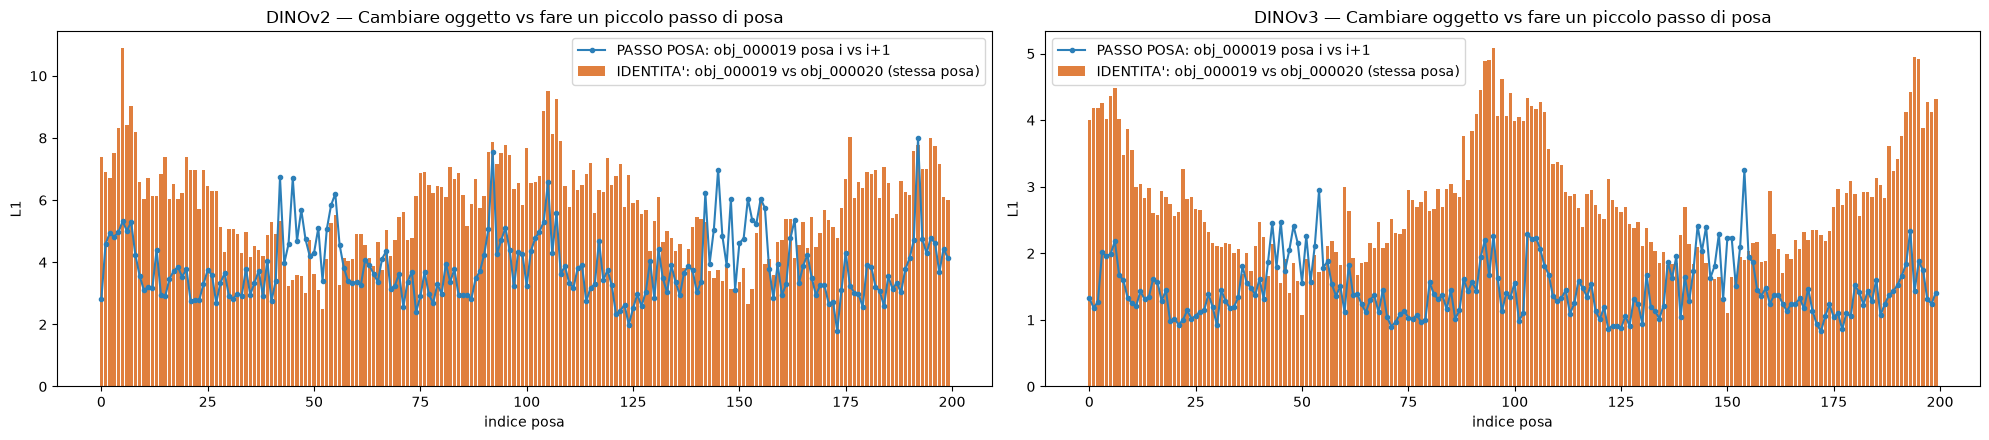

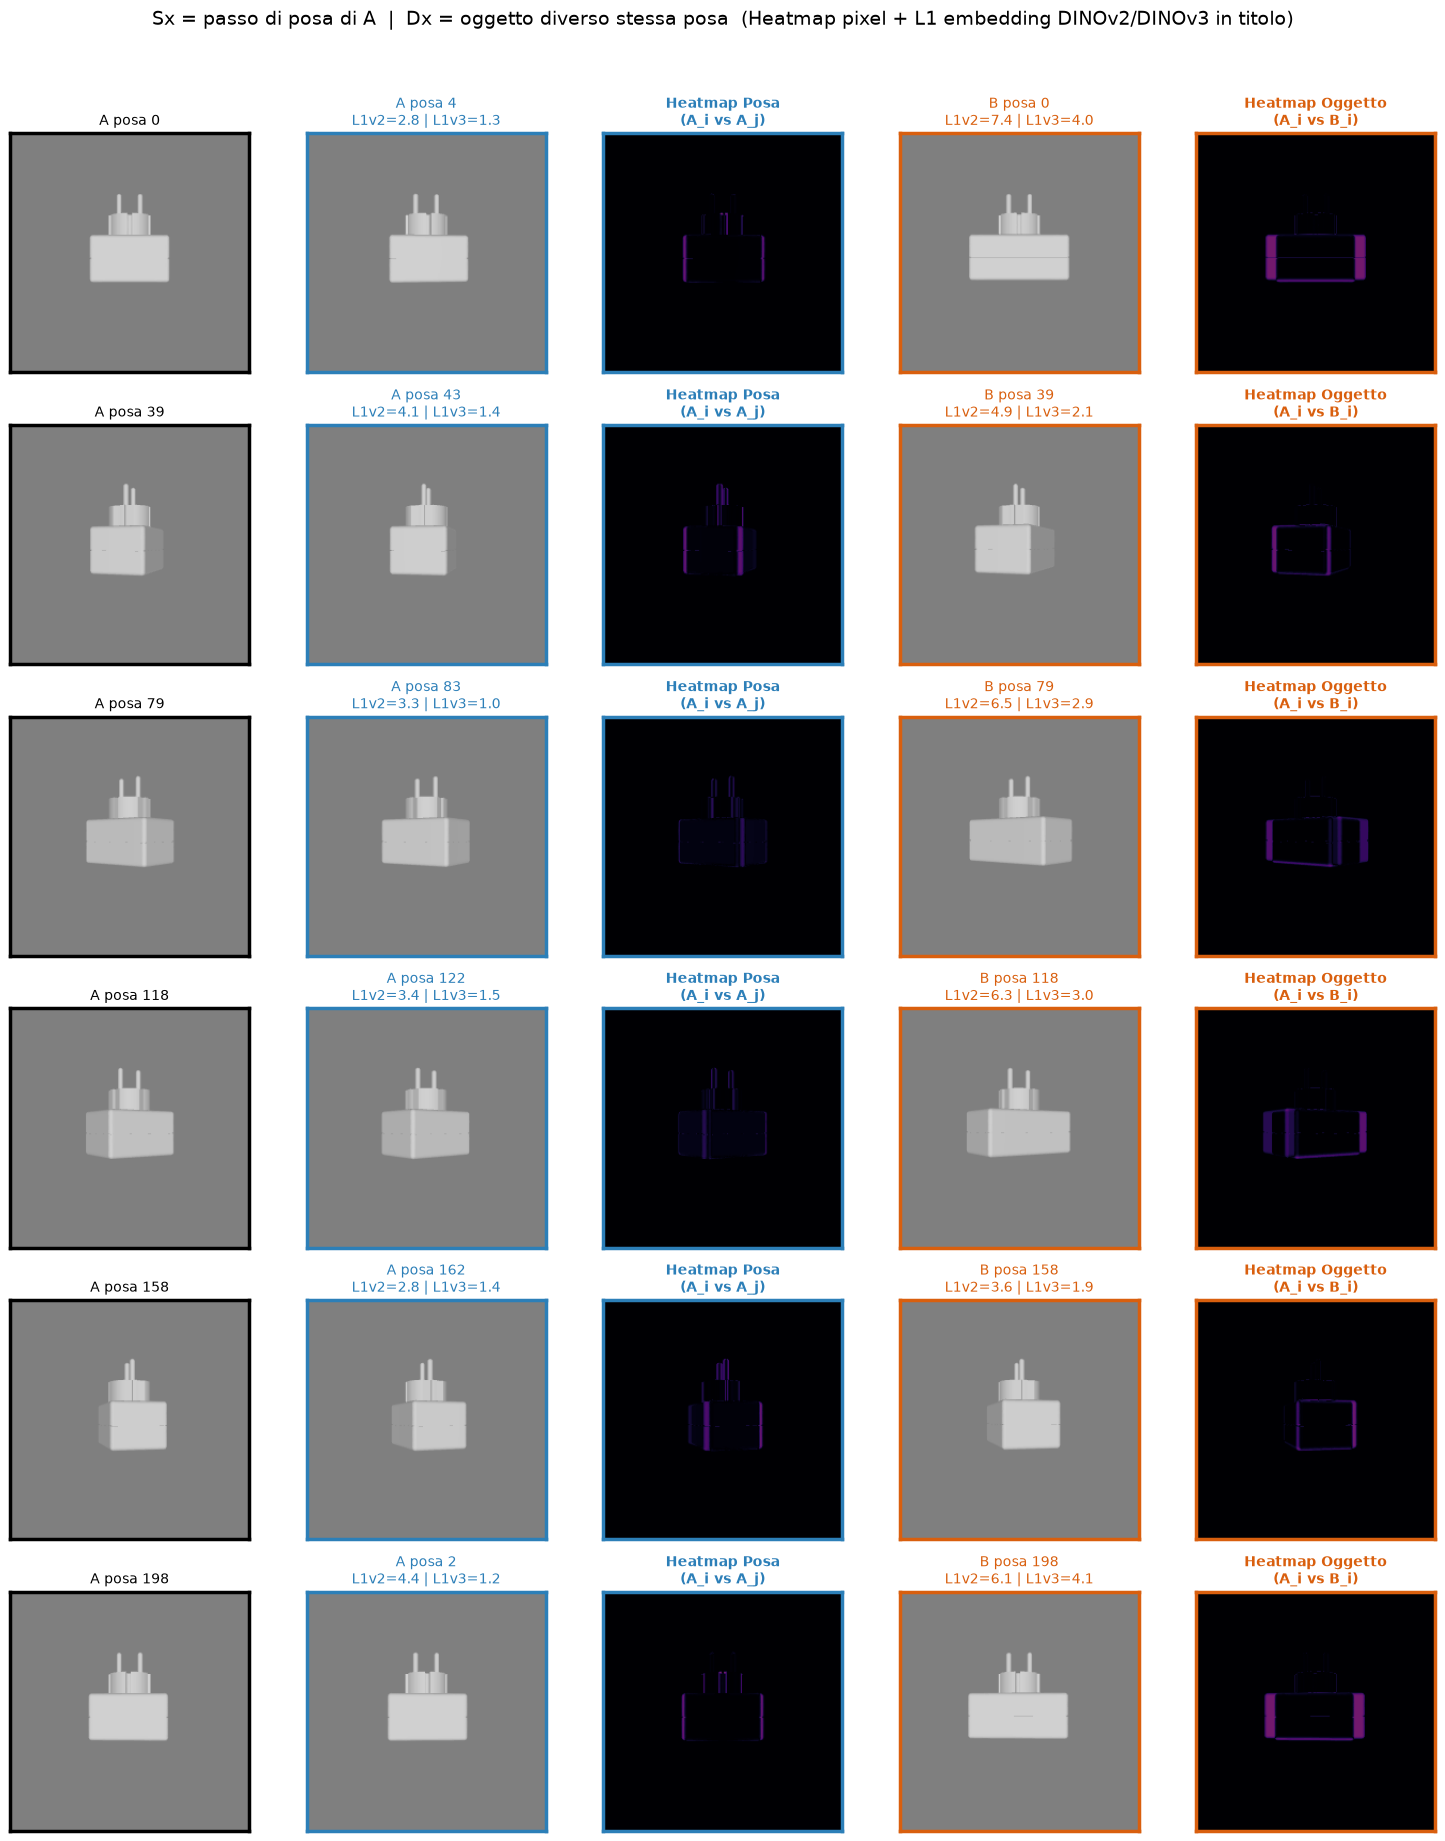

In [11]:
import pandas as pd
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ================= CONFIG =================

DATASET = "tless_translation"
OBJ_A, OBJ_B = "obj_000019", "obj_000020"
TOKEN = "pool"

# ================= CARICAMENTO + ALLINEAMENTO POSE =================

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object == OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object == OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B))
A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")

if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

# ================= EMBEDDING (DINOv2 + DINOv3) =================

def emb_v2(row, token=TOKEN):
    return extract_featuresv2(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

def emb_v3(row, token=TOKEN):
    return extract_featuresv3(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

print("Estraggo embedding DINOv2...")
embA_v2 = [emb_v2(A.iloc[i]) for i in range(n)]
embB_v2 = [emb_v2(B.iloc[i]) for i in range(n)]

print("Estraggo embedding DINOv3...")
embA_v3 = [emb_v3(A.iloc[i]) for i in range(n)]
embB_v3 = [emb_v3(B.iloc[i]) for i in range(n)]

def compute_ident_step(embA, embB, n):
    ident, step = [], []
    for i in range(n):
        ident.append(torch.abs(embA[i] - embB[i]).sum().item())   # A vs B, stessa posa
        j = (i + 1) % n
        step.append(torch.abs(embA[i] - embA[j]).sum().item())    # A posa i vs A posa i+1
    return np.array(ident), np.array(step)

ident_v2, step_v2 = compute_ident_step(embA_v2, embB_v2, n)
ident_v3, step_v3 = compute_ident_step(embA_v3, embB_v3, n)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA (affiancato v2 | v3) ---
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5), sharey=False)
x = np.arange(n)

model_data = [
    ("DINOv2", ident_v2, step_v2, axes[0]),
    ("DINOv3", ident_v3, step_v3, axes[1]),
]

for name, ident, step, ax in model_data:
    ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
    ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
    ax.set_xlabel("indice posa")
    ax.set_ylabel("L1")
    ax.set_title(f"{name} — Cambiare oggetto vs fare un piccolo passo di posa")
    ax.legend()

plt.tight_layout()
plt.show()

# ==========================================
# --- GRAFICO 2: IMMAGINI E HEATMAP (con L1 di entrambi i modelli in titolo) ---
# ==========================================

SEL = np.linspace(0, n - 2, 6).astype(int)
fig, axes = plt.subplots(len(SEL), 5, figsize=(15, 3 * len(SEL)))

for r, i in enumerate(SEL):
    j = (i + 4) % n
    imgA_i = np.array(Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    imgA_j = np.array(Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB"), dtype=np.float32)
    imgB_i = np.array(Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB"), dtype=np.float32)

    diff_pose = np.abs(imgA_i - imgA_j).mean(axis=2)
    diff_obj = np.abs(imgA_i - imgB_i).mean(axis=2)

    imgs = [imgA_i, imgA_j, diff_pose, imgB_i, diff_obj]
    titles = [
        f"A posa {i}",
        f"A posa {j}\nL1v2={step_v2[i]:.1f} | L1v3={step_v3[i]:.1f}",
        "Heatmap Posa\n(A_i vs A_j)",
        f"B posa {i}\nL1v2={ident_v2[i]:.1f} | L1v3={ident_v3[i]:.1f}",
        "Heatmap Oggetto\n(A_i vs B_i)",
    ]
    cols = ["black", "#2c7fb8", "#2c7fb8", "#d95f0e", "#d95f0e"]

    for c, (img, t, col) in enumerate(zip(imgs, titles, cols)):
        if "Heatmap" in t:
            axes[r, c].imshow(img, cmap="inferno", vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(t, fontsize=10, color=col,
                              fontweight='bold' if "Heatmap" in t else 'normal')
        for s in axes[r, c].spines.values():
            s.set_color(col)
            s.set_linewidth(2.5)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])

plt.suptitle("Sx = passo di posa di A  |  Dx = oggetto diverso stessa posa  "
             "(Heatmap pixel + L1 embedding DINOv2/DINOv3 in titolo)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

pose allineate (rotazione + traslazione): False
tz di A: -279.00  |  tz di B: -274.93
riallineati su 200 pose comuni — rotazioni allineate: True
Estraggo embedding DINOv2...
Estraggo embedding DINOv3...


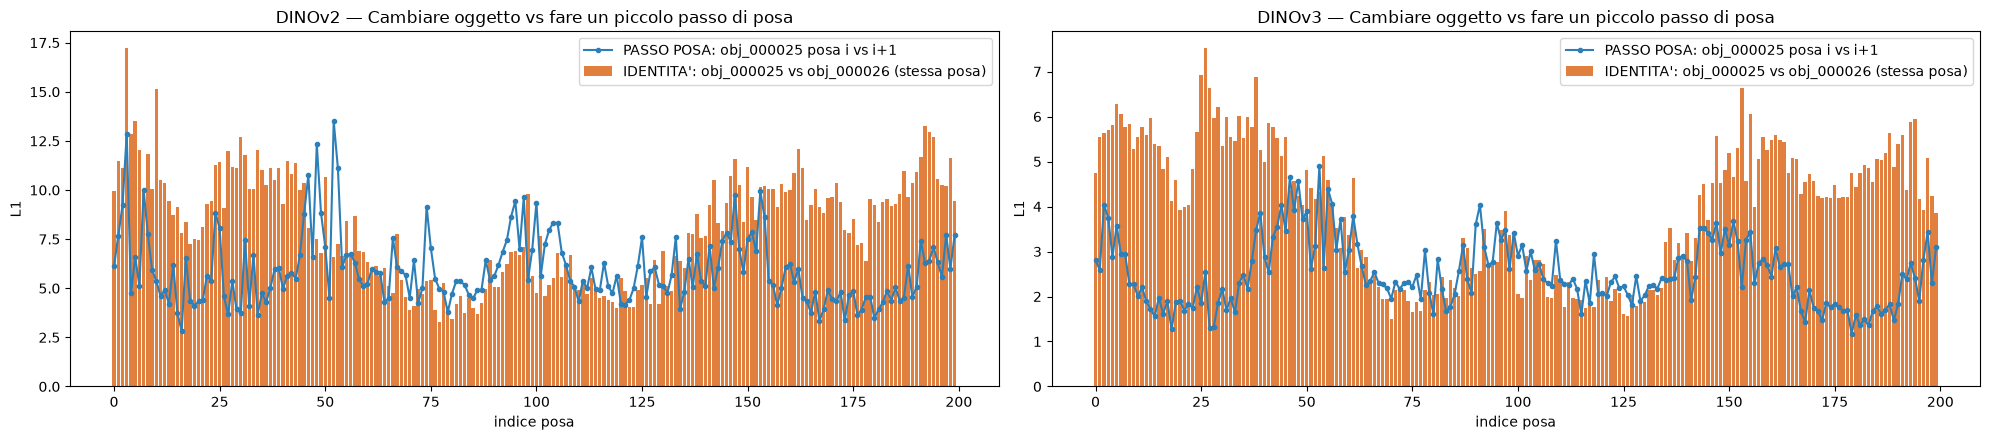

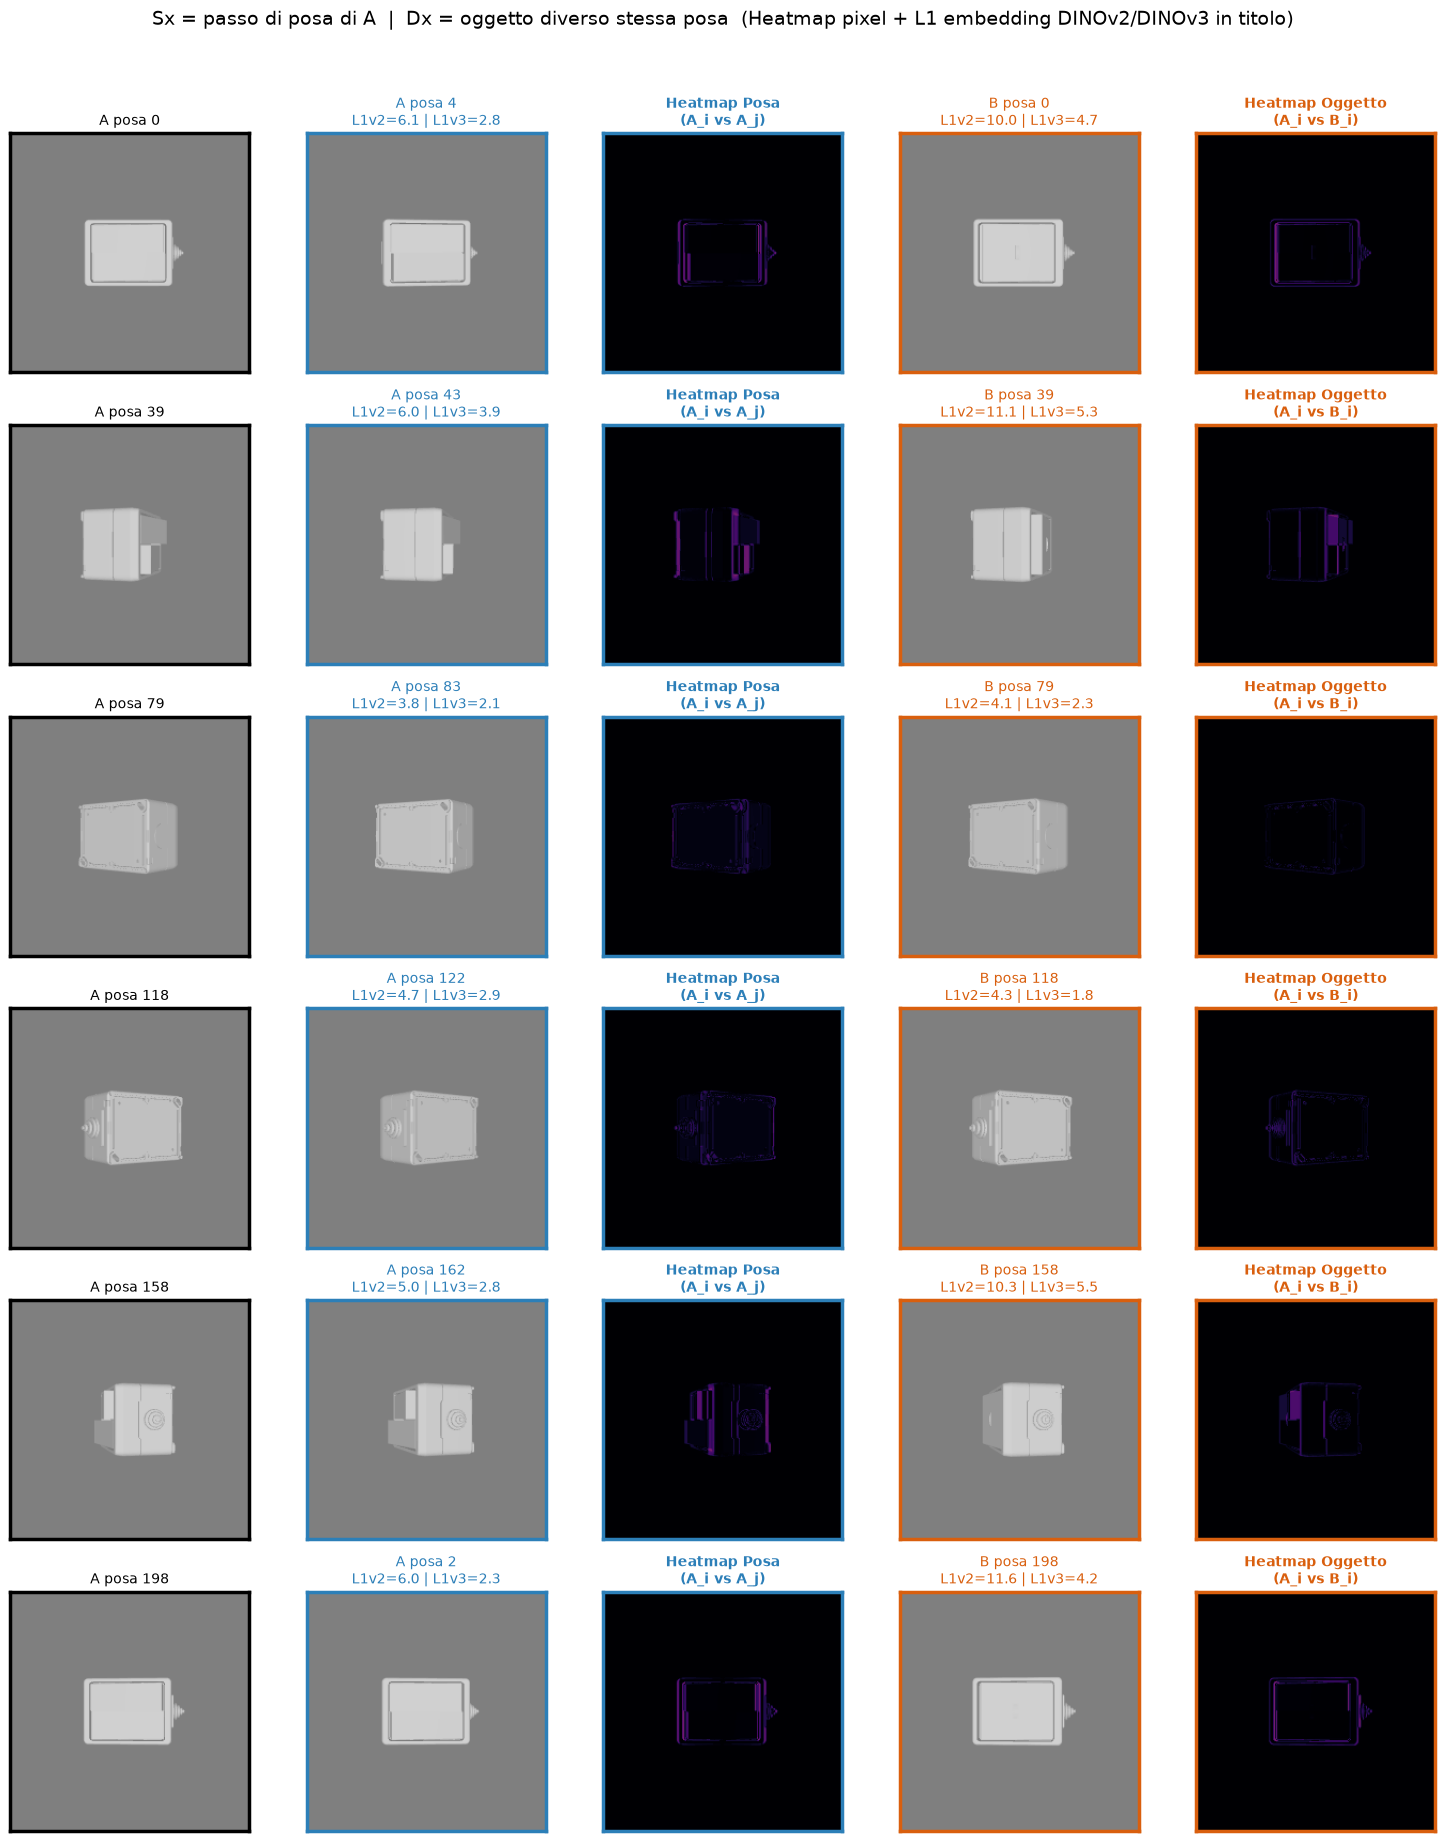

In [12]:
import pandas as pd
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ================= CONFIG =================

DATASET = "tless_translation"
OBJ_A, OBJ_B = "obj_000025", "obj_000026"
TOKEN = "pool"

# ================= CARICAMENTO + ALLINEAMENTO POSE =================

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object == OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object == OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B))
A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")

if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

# ================= EMBEDDING (DINOv2 + DINOv3) =================

def emb_v2(row, token=TOKEN):
    return extract_featuresv2(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

def emb_v3(row, token=TOKEN):
    return extract_featuresv3(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

print("Estraggo embedding DINOv2...")
embA_v2 = [emb_v2(A.iloc[i]) for i in range(n)]
embB_v2 = [emb_v2(B.iloc[i]) for i in range(n)]

print("Estraggo embedding DINOv3...")
embA_v3 = [emb_v3(A.iloc[i]) for i in range(n)]
embB_v3 = [emb_v3(B.iloc[i]) for i in range(n)]

def compute_ident_step(embA, embB, n):
    ident, step = [], []
    for i in range(n):
        ident.append(torch.abs(embA[i] - embB[i]).sum().item())   # A vs B, stessa posa
        j = (i + 1) % n
        step.append(torch.abs(embA[i] - embA[j]).sum().item())    # A posa i vs A posa i+1
    return np.array(ident), np.array(step)

ident_v2, step_v2 = compute_ident_step(embA_v2, embB_v2, n)
ident_v3, step_v3 = compute_ident_step(embA_v3, embB_v3, n)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA (affiancato v2 | v3) ---
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5), sharey=False)
x = np.arange(n)

model_data = [
    ("DINOv2", ident_v2, step_v2, axes[0]),
    ("DINOv3", ident_v3, step_v3, axes[1]),
]

for name, ident, step, ax in model_data:
    ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
    ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
    ax.set_xlabel("indice posa")
    ax.set_ylabel("L1")
    ax.set_title(f"{name} — Cambiare oggetto vs fare un piccolo passo di posa")
    ax.legend()

plt.tight_layout()
plt.show()

# ==========================================
# --- GRAFICO 2: IMMAGINI E HEATMAP (con L1 di entrambi i modelli in titolo) ---
# ==========================================

SEL = np.linspace(0, n - 2, 6).astype(int)
fig, axes = plt.subplots(len(SEL), 5, figsize=(15, 3 * len(SEL)))

for r, i in enumerate(SEL):
    j = (i + 4) % n
    imgA_i = np.array(Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB"), dtype=np.float32)
    imgA_j = np.array(Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB"), dtype=np.float32)
    imgB_i = np.array(Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB"), dtype=np.float32)

    diff_pose = np.abs(imgA_i - imgA_j).mean(axis=2)
    diff_obj = np.abs(imgA_i - imgB_i).mean(axis=2)

    imgs = [imgA_i, imgA_j, diff_pose, imgB_i, diff_obj]
    titles = [
        f"A posa {i}",
        f"A posa {j}\nL1v2={step_v2[i]:.1f} | L1v3={step_v3[i]:.1f}",
        "Heatmap Posa\n(A_i vs A_j)",
        f"B posa {i}\nL1v2={ident_v2[i]:.1f} | L1v3={ident_v3[i]:.1f}",
        "Heatmap Oggetto\n(A_i vs B_i)",
    ]
    cols = ["black", "#2c7fb8", "#2c7fb8", "#d95f0e", "#d95f0e"]

    for c, (img, t, col) in enumerate(zip(imgs, titles, cols)):
        if "Heatmap" in t:
            axes[r, c].imshow(img, cmap="inferno", vmin=0, vmax=255)
        else:
            axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(t, fontsize=10, color=col,
                              fontweight='bold' if "Heatmap" in t else 'normal')
        for s in axes[r, c].spines.values():
            s.set_color(col)
            s.set_linewidth(2.5)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])

plt.suptitle("Sx = passo di posa di A  |  Dx = oggetto diverso stessa posa  "
             "(Heatmap pixel + L1 embedding DINOv2/DINOv3 in titolo)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

pose allineate (rotazione + traslazione): False
tz di A: -257.15  |  tz di B: -259.36
riallineati su 200 pose comuni — rotazioni allineate: True
Estraggo embedding DINOv2...
Estraggo embedding DINOv3...


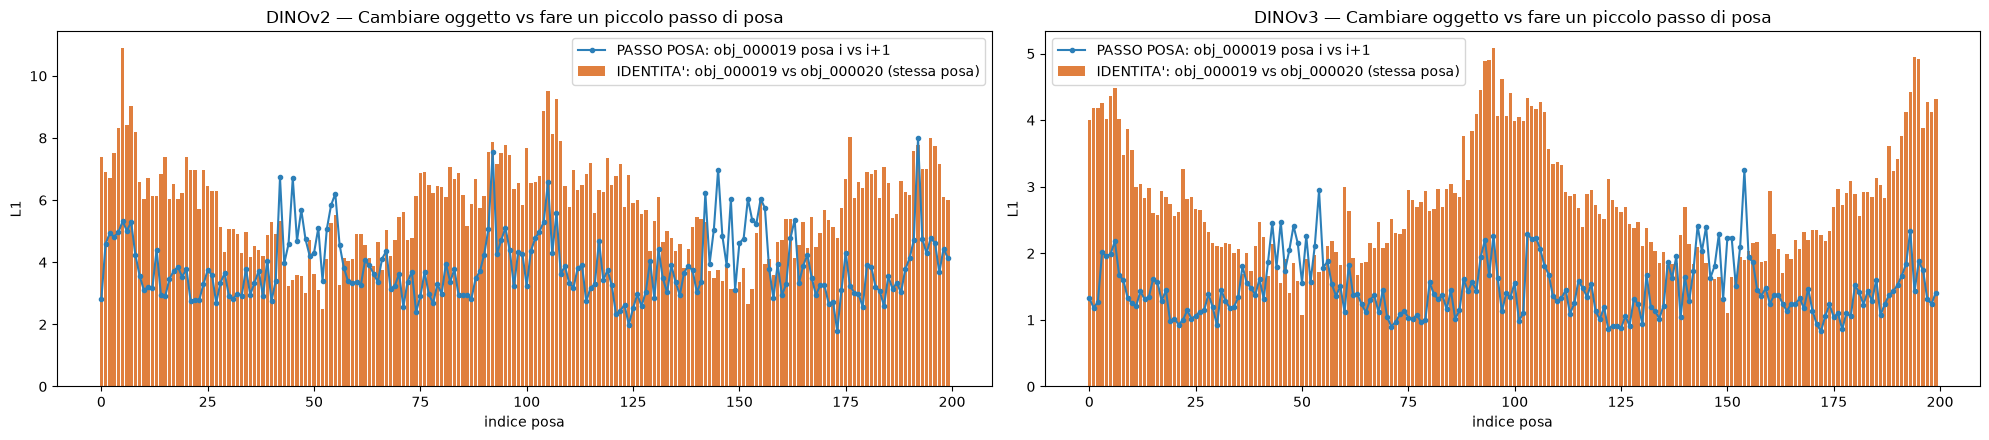

Solo DINOv2 sbaglia: 11 / 200
Solo DINOv3 sbaglia: 6 / 200
Entrambi sbagliano:  18 / 200
Entrambi corretti:   165 / 200


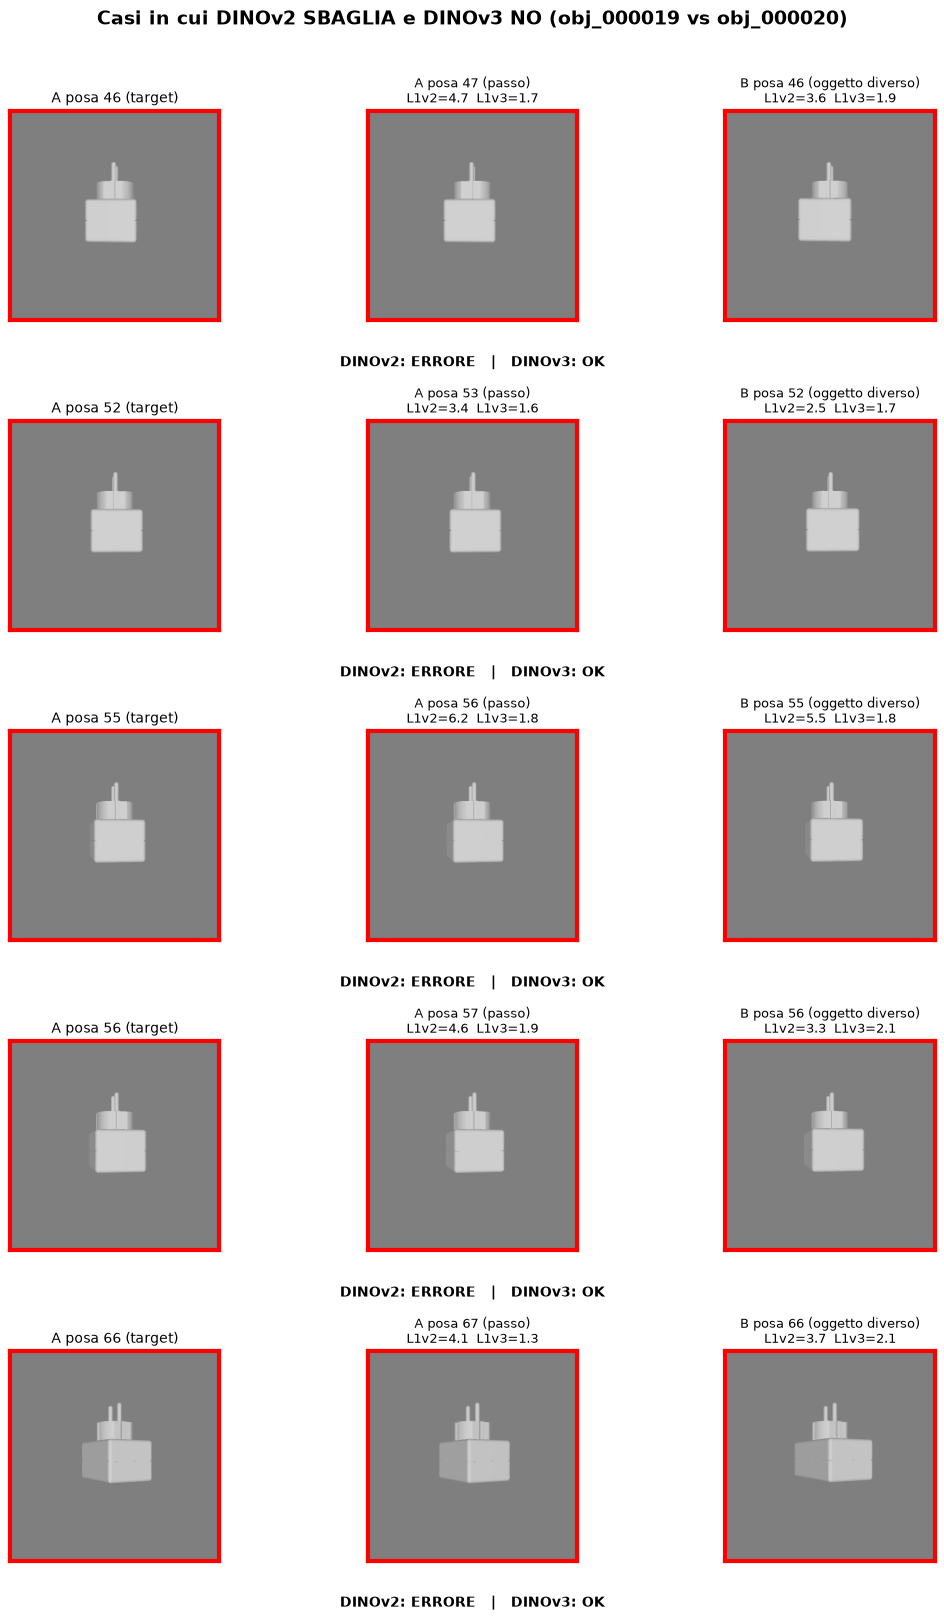

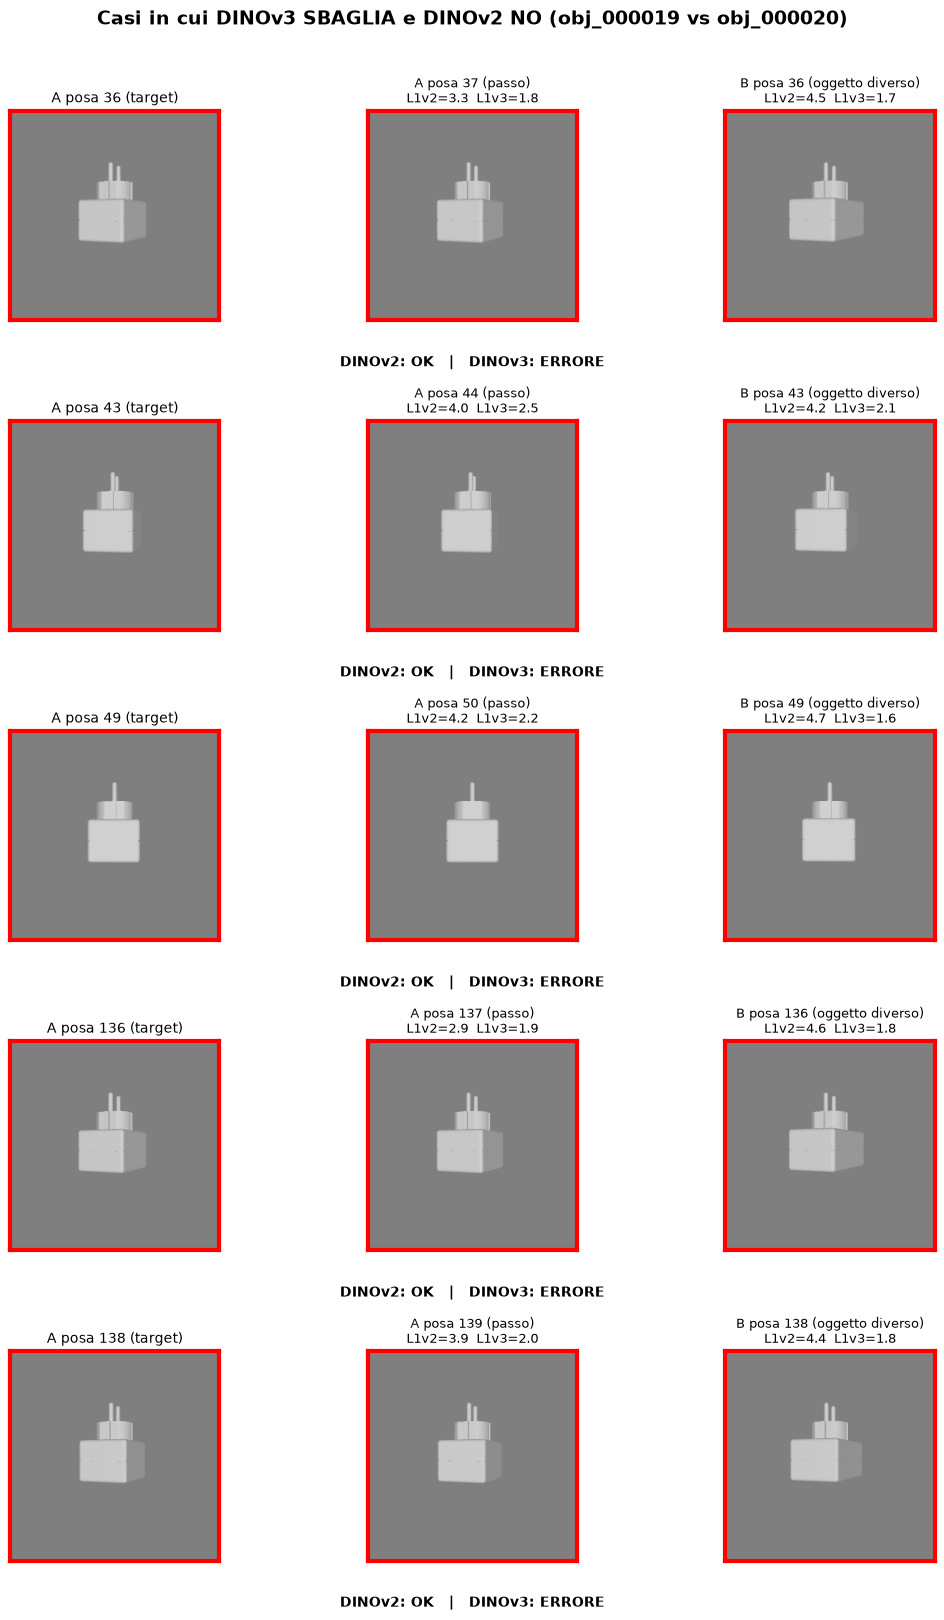

In [13]:
import pandas as pd
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ================= CONFIG =================

DATASET = "tless_translation"
OBJ_A, OBJ_B = "obj_000019", "obj_000020"
TOKEN = "pool"

# ================= CARICAMENTO + ALLINEAMENTO POSE =================

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
A = df[df.object == OBJ_A].sort_values("pose_idx").reset_index(drop=True)
B = df[df.object == OBJ_B].sort_values("pose_idx").reset_index(drop=True)
n = min(len(A), len(B))
A, B = A.iloc[:n].reset_index(drop=True), B.iloc[:n].reset_index(drop=True)

# --- verifica allineamento posa COMPLETA (rotazione + traslazione) ---
rc = [f"r{a}{b}" for a in range(3) for b in range(3)]
pose_cols = rc + ["tx", "ty", "tz"]
aligned = np.allclose(A[pose_cols].values, B[pose_cols].values, atol=1e-5)
print("pose allineate (rotazione + traslazione):", aligned)
print(f"tz di A: {A['tz'].iloc[0]:.2f}  |  tz di B: {B['tz'].iloc[0]:.2f}")

if not aligned:
    common = sorted(set(A.pose_idx) & set(B.pose_idx))
    A = A[A.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    B = B[B.pose_idx.isin(common)].sort_values("pose_idx").reset_index(drop=True)
    n = len(A)
    # controllo solo la ROTAZIONE dopo il riallineamento (la tz puo' differire per scala oggetto)
    rot_ok = np.allclose(A[rc].values, B[rc].values, atol=1e-5)
    print(f"riallineati su {n} pose comuni — rotazioni allineate: {rot_ok}")
    if not rot_ok:
        print("ATTENZIONE: rotazioni ancora disallineate, il confronto 'stessa posa' non e' valido")

# ================= EMBEDDING (DINOv2 + DINOv3) =================

def emb_v2(row, token=TOKEN):
    return extract_featuresv2(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

def emb_v3(row, token=TOKEN):
    return extract_featuresv3(Image.open(RENDERS / row["image"]).convert("RGB"), token=token)

print("Estraggo embedding DINOv2...")
embA_v2 = [emb_v2(A.iloc[i]) for i in range(n)]
embB_v2 = [emb_v2(B.iloc[i]) for i in range(n)]

print("Estraggo embedding DINOv3...")
embA_v3 = [emb_v3(A.iloc[i]) for i in range(n)]
embB_v3 = [emb_v3(B.iloc[i]) for i in range(n)]

def compute_ident_step(embA, embB, n):
    ident, step = [], []
    for i in range(n):
        ident.append(torch.abs(embA[i] - embB[i]).sum().item())   # A vs B, stessa posa
        j = (i + 1) % n
        step.append(torch.abs(embA[i] - embA[j]).sum().item())    # A posa i vs A posa i+1
    return np.array(ident), np.array(step)

ident_v2, step_v2 = compute_ident_step(embA_v2, embB_v2, n)
ident_v3, step_v3 = compute_ident_step(embA_v3, embB_v3, n)

# ==========================================
# --- GRAFICO 1: IDENTITÀ VS PASSO POSA (affiancato v2 | v3) ---
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5), sharey=False)
x = np.arange(n)

model_data = [
    ("DINOv2", ident_v2, step_v2, axes[0]),
    ("DINOv3", ident_v3, step_v3, axes[1]),
]

for name, ident, step, ax in model_data:
    ax.bar(x, ident, color="#d95f0e", alpha=0.8, label=f"IDENTITA': {OBJ_A} vs {OBJ_B} (stessa posa)")
    ax.plot(x, step, "o-", color="#2c7fb8", ms=3, label=f"PASSO POSA: {OBJ_A} posa i vs i+1")
    ax.set_xlabel("indice posa")
    ax.set_ylabel("L1")
    ax.set_title(f"{name} — Cambiare oggetto vs fare un piccolo passo di posa")
    ax.legend()

plt.tight_layout()
plt.show()

# ==========================================
# --- ANALISI ERRORI: step > ident significa che il modello ritiene
#     un piccolo passo di posa (stesso oggetto) piu' "diverso" di un
#     oggetto completamente diverso alla stessa posa -> ERRORE.
# ==========================================

err_v2 = step_v2 > ident_v2
err_v3 = step_v3 > ident_v3

only_v2_wrong = np.where(err_v2 & ~err_v3)[0]   # v2 sbaglia, v3 no
only_v3_wrong = np.where(err_v3 & ~err_v2)[0]   # v3 sbaglia, v2 no
both_wrong    = np.where(err_v2 & err_v3)[0]
both_ok       = np.where(~err_v2 & ~err_v3)[0]

print(f"Solo DINOv2 sbaglia: {len(only_v2_wrong)} / {n}")
print(f"Solo DINOv3 sbaglia: {len(only_v3_wrong)} / {n}")
print(f"Entrambi sbagliano:  {len(both_wrong)} / {n}")
print(f"Entrambi corretti:   {len(both_ok)} / {n}")

def _plot_error_cases(indici, titolo_generale, model_in_focus, max_esempi=5):
    """
    model_in_focus: "v2" o "v3" -> determina il colore del bordo
    (quale dei due modelli e' quello "sotto esame" in questo blocco).
    """
    if len(indici) == 0:
        print(f"Nessun caso per: {titolo_generale}")
        return
    sel = indici[:max_esempi]
    fig, axes = plt.subplots(len(sel), 3, figsize=(11, 3.2 * len(sel)))
    if len(sel) == 1:
        axes = axes.reshape(1, -1)

    err_focus = err_v2 if model_in_focus == "v2" else err_v3

    for r, i in enumerate(sel):
        j = (i + 1) % n   # stessa definizione di "passo" usata nel calcolo di step[]
        imgA_i = Image.open(RENDERS / A.iloc[i]["image"]).convert("RGB")
        imgA_j = Image.open(RENDERS / A.iloc[j]["image"]).convert("RGB")
        imgB_i = Image.open(RENDERS / B.iloc[i]["image"]).convert("RGB")

        col = "red" if err_focus[i] else "green"

        axes[r, 0].imshow(imgA_i)
        axes[r, 0].set_title(f"A posa {i} (target)", fontsize=10)

        axes[r, 1].imshow(imgA_j)
        axes[r, 1].set_title(
            f"A posa {j} (passo)\n"
            f"L1v2={step_v2[i]:.1f}  L1v3={step_v3[i]:.1f}",
            fontsize=9)

        axes[r, 2].imshow(imgB_i)
        axes[r, 2].set_title(
            f"B posa {i} (oggetto diverso)\n"
            f"L1v2={ident_v2[i]:.1f}  L1v3={ident_v3[i]:.1f}",
            fontsize=9)

        verdetto = (f"DINOv2: {'ERRORE' if err_v2[i] else 'OK'}   |   "
                    f"DINOv3: {'ERRORE' if err_v3[i] else 'OK'}")
        axes[r, 1].text(0.5, -0.22, verdetto, transform=axes[r, 1].transAxes,
                         ha='center', fontsize=10, fontweight='bold')

        # bordo rosso/verde su tutta la riga, in base al modello in focus in questo blocco
        for c in range(3):
            for s in axes[r, c].spines.values():
                s.set_color(col)
                s.set_linewidth(3)
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

    plt.suptitle(titolo_generale, y=1.01, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

_plot_error_cases(only_v2_wrong,
                   f"Casi in cui DINOv2 SBAGLIA e DINOv3 NO ({OBJ_A} vs {OBJ_B})",
                   model_in_focus="v2")
_plot_error_cases(only_v3_wrong,
                   f"Casi in cui DINOv3 SBAGLIA e DINOv2 NO ({OBJ_A} vs {OBJ_B})",
                   model_in_focus="v3")